notebooks/eda.ipynb:
 - Visualizations and descriptive stats.
 - Missingness analysis.
 - Correlation heatmaps, scatterplots, outlier checks.
 - Exploratory lag analysis (ACF/PACF, lag vs. target plots).

In [14]:
date = "200202"

if date:
    theta_path = "../data_excerpt/theta/theta2pvu_" + date + ".grib"
    uv_path = "../data_excerpt/uv/uv300_" + date + ".grib"
else:
    theta_path = "../data_excerpt/theta/theta2pvu_199812.grib"
    uv_path = "../data_excerpt/uv/uv300_199812.grib"

In [15]:
import sys
import numpy as np

# Make sure Python can find plot_era40.py in the parent directory
sys.path.append("..")
from plot_era40 import NAMES, read

# 1. First, just get available times in the current grib
# If calling read without a time returns times as the 3rd element:
_, _, theta_times, _ = read(theta_path, NAMES["theta"])
_, _, uv_times, _ = read(uv_path, NAMES["uv"])

# 2. Now load the grid using the first available time
first_theta_time = theta_times[0]
first_uv_time = uv_times[0]
theta_lats, theta_lons, _, theta_fields = read(theta_path, NAMES["theta"], first_theta_time)
uv_lats, uv_lons, _, uv_fields = read(uv_path, NAMES["uv"], first_uv_time)

print(f"Grid Dimensions: {theta_lons.size} Longitudes x {theta_lats.size} Latitudes")
print(f"Total Time Steps: {len(theta_times)}")
print(f"Date Range: {theta_times[0]} to {theta_times[-1]}")

Grid Dimensions: 320 Longitudes x 160 Latitudes
Total Time Steps: 112
Date Range: 2002-02-01 00:00:00 to 2002-02-28 18:00:00


In [16]:
# Pick a specific analysis time
when = theta_times[0]
lats, lons, _, fields = read(theta_path, NAMES["theta"], when)

print(f"\n--- Structure of GRIB file for Analysis Time: {when} ---")
for field_name, data in fields.items():
    print(f"\nField: {field_name}")
    print(f"  Shape: {data.shape}")
    print(f"  Missing (NaN) values: {np.isnan(data).sum()}")
    print(f"  Mean:   {np.nanmean(data):.4f}")
    print(f"  Std:    {np.nanstd(data):.4f}")
    print(f"  Min:    {np.nanmin(data):.4f}")
    print(f"  Max:    {np.nanmax(data):.4f}")


--- Structure of GRIB file for Analysis Time: 2002-02-01 00:00:00 ---

Field: pt
  Shape: (160, 320)
  Missing (NaN) values: 0
  Mean:   332.2298
  Std:    32.6315
  Min:    258.5205
  Max:    404.1377


In [17]:
field_name = list(fields.keys())[0]
data = fields[field_name]

mean_val = np.nanmean(data)
std_val = np.nanstd(data)

# Find grid cells exceeding 3 standard deviations
outlier_mask = np.abs(data - mean_val) > (3 * std_val)
num_outliers = np.sum(outlier_mask)

print(f"Field '{field_name}' from theta file has {num_outliers} grid cells exceeding 3 standard deviations.")

Field 'pt' from theta file has 0 grid cells exceeding 3 standard deviations.


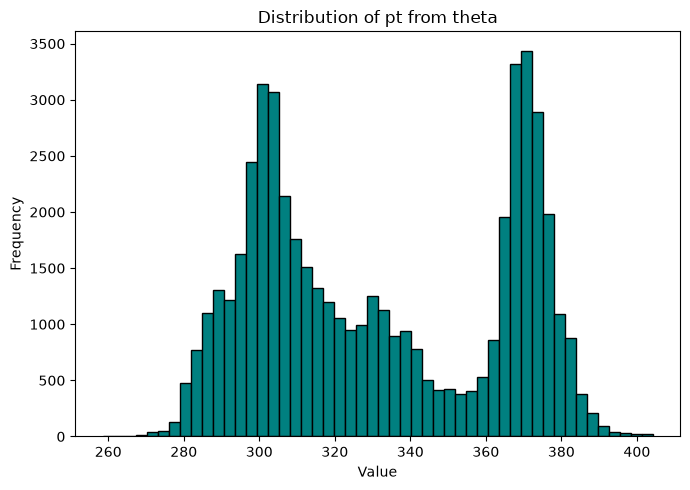

In [18]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 1, figsize=(7, 5))

# 1. Distribution Histogram (checks for skewness or weird data spikes)
axes.hist(data.ravel(), bins=50, color='teal', edgecolor='black')
axes.set_title(f"Distribution of {field_name} from theta")
axes.set_xlabel("Value")
axes.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [ ]:
def process_step(month, manipulate_frame_function):

    theta_path = "../data_excerpt/theta/theta2pvu_" + month + ".grib"
    uv_path = "../data_excerpt/uv/uv300_" + month + ".grib"

    # Assumes both theta and uv both have existing and matching times
    _, _, times, _ = read(theta_path, NAMES["theta"])

    # Loop through every single time step, read the file, and process a step
    for i, t in enumerate(times):

        time_str = t.strftime("%Y-%m-%dT%H")

        # Load the grid using each available time
        theta_lats, theta_lons, _, theta_fields = read(theta_path, NAMES["theta"], t)
        uv_lats, uv_lons, _, uv_fields = read(uv_path, NAMES["uv"], t)

        return manipulate_frame_function(theta_lats, theta_lons, uv_lats, uv_lons)

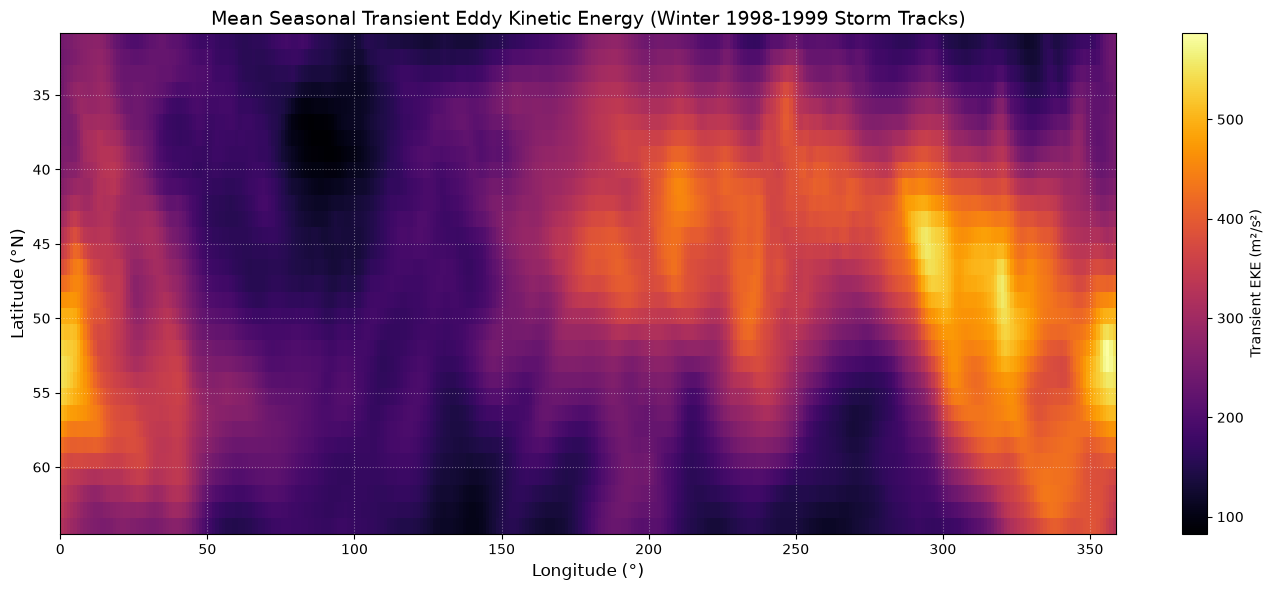

In [39]:
import numpy as np
import matplotlib.pyplot as plt

# winter season months, Dec 1998-Feb 1999
months = ["199812", "199901", "199902"]

u_list, v_list = [], []
uv_lats, uv_lons = None, None
lat_mask = None
trimmed_lats = None

# Loop through each month and collect data
for m in months:
    uv_path = f"../data_excerpt/uv/uv300_{m}.grib"
    
    # Read times for this month's file
    _, _, times, _ = read(uv_path, NAMES["uv"])
    
    # Initialize grid and lat mask using the first file/time
    if uv_lats is None:
        uv_lats, uv_lons, _, _ = read(uv_path, NAMES["uv"], times[0])
        lat_mask = (uv_lats >= 30) & (uv_lats <= 65)
        trimmed_lats = uv_lats[lat_mask]
    
    # Collect all time steps for this month
    for t in times:
        _, _, _, fields = read(uv_path, NAMES["uv"], t)
        
        keys = list(fields.keys())
        u_data = fields[keys[0]]
        v_data = fields[keys[1]]
        
        u_list.append(u_data[lat_mask, :])
        v_list.append(v_data[lat_mask, :])

# Concatenate all months into a single seasonal array
u_arr = np.array(u_list)  # Shape: (total_seasonal_steps, trimmed_lats, lons)
v_arr = np.array(v_list)

# 1. Compute seasonal mean to isolate high-frequency transient anomalies (u' and v')
u_mean = np.nanmean(u_arr, axis=0, keepdims=True)
v_mean = np.nanmean(v_arr, axis=0, keepdims=True)

u_prime = u_arr - u_mean
v_prime = v_arr - v_mean

# 2. Calculate Instantaneous EKE per time step, then average over the season
eke_instantaneous = 0.5 * (u_prime**2 + v_prime**2)
mean_eke = np.nanmean(eke_instantaneous, axis=0)  # Shape: (trimmed_lats, lons)

# 3. Plot the resulting seasonal EKE storm track map
plt.figure(figsize=(14, 6))

im = plt.imshow(
    mean_eke,
    origin="lower",
    extent=[uv_lons[0], uv_lons[-1], trimmed_lats[0], trimmed_lats[-1]],
    cmap="inferno",
    aspect="auto"
)

plt.colorbar(im, label="Transient EKE (m²/s²)")
plt.title("Mean Seasonal Transient Eddy Kinetic Energy (Winter 1998-1999 Storm Tracks)", fontsize=14)
plt.xlabel("Longitude (°)", fontsize=12)
plt.ylabel("Latitude (°N)", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.4, color="white")

plt.tight_layout()
plt.show()

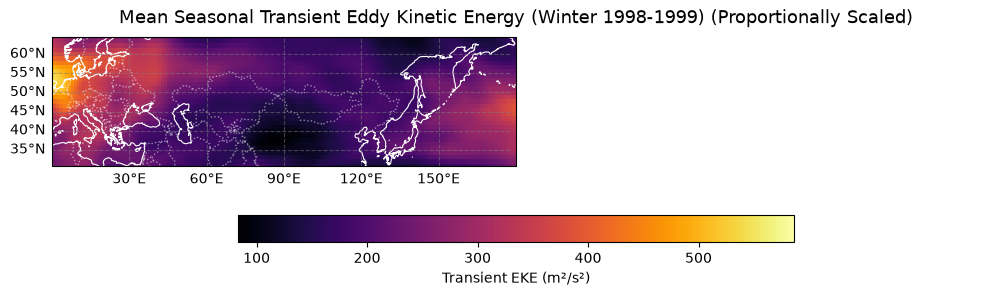

In [51]:
import matplotlib.pyplot as plt
import numpy as np

# Check for Cartopy availability
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    from cartopy.util import add_cyclic_point
    HAVE_CARTOPY = True
except ImportError:
    HAVE_CARTOPY = False

# Use a wider, shorter figure size tailored for a mid-latitude strip
plt.figure(figsize=(10, 3.3))

if HAVE_CARTOPY:
    # Use standard PlateCarree matching your 0-360 data structure
    ax = plt.axes(projection=ccrs.PlateCarree())
    
    # Add cyclic point to close the seam smoothly
    eke_cyclic, lons_cyclic = add_cyclic_point(mean_eke, coord=uv_lons, axis=1)
    
    # Create 2D mesh grids
    lon2d, lat2d = np.meshgrid(lons_cyclic, trimmed_lats)
    
    # Plot using pcolormesh
    im = ax.pcolormesh(
        lon2d, lat2d, eke_cyclic,
        transform=ccrs.PlateCarree(),
        cmap="inferno",
        shading="auto"
    )
    
    # Set limits explicitly
    ax.set_xlim(lons_cyclic.min(), lons_cyclic.max())
    ax.set_ylim(trimmed_lats.min(), trimmed_lats.max())
    
    # Fix the map aspect ratio based on the central latitude cosine scale
    # This prevents the north-south or east-west squishing artifacts
    center_lat_rad = np.deg2rad(np.mean(trimmed_lats))
    ax.set_aspect(1.0 / np.cos(center_lat_rad))
    
    # Add map overlays
    ax.coastlines(resolution="50m", color="white", linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linestyle=":", edgecolor="white", alpha=0.5)
    ax.add_feature(cfeature.LAND, facecolor="lightgray", alpha=0.2)
    
    # Add gridlines with labels
    gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False, color="gray", alpha=0.5, linestyle="--")
    gl.top_labels = False
    gl.right_labels = False
    
    title_suffix = " (Proportionally Scaled)"
else:
    # Fallback if Cartopy is missing
    im = plt.imshow(
        mean_eke,
        origin="lower",
        extent=[uv_lons[0], uv_lons[-1], trimmed_lats[0], trimmed_lats[-1]],
        cmap="inferno",
        aspect="auto"
    )
    plt.xlabel("Longitude (°)")
    plt.ylabel("Latitude (°N)")
    plt.grid(True, linestyle=":", alpha=0.4, color="white")
    title_suffix = " (Standard Grid)"

# Colorbar and formatting (tucked neatly underneath)
plt.colorbar(im, label="Transient EKE (m²/s²)", orientation="horizontal", pad=0.18, shrink=0.6)
plt.title(f"Mean Seasonal Transient Eddy Kinetic Energy (Winter 1998-1999){title_suffix}", fontsize=13, pad=10)

plt.tight_layout()
plt.show()

Variance explained by EOF1: 8.48%
Variance explained by EOF2: 6.49%


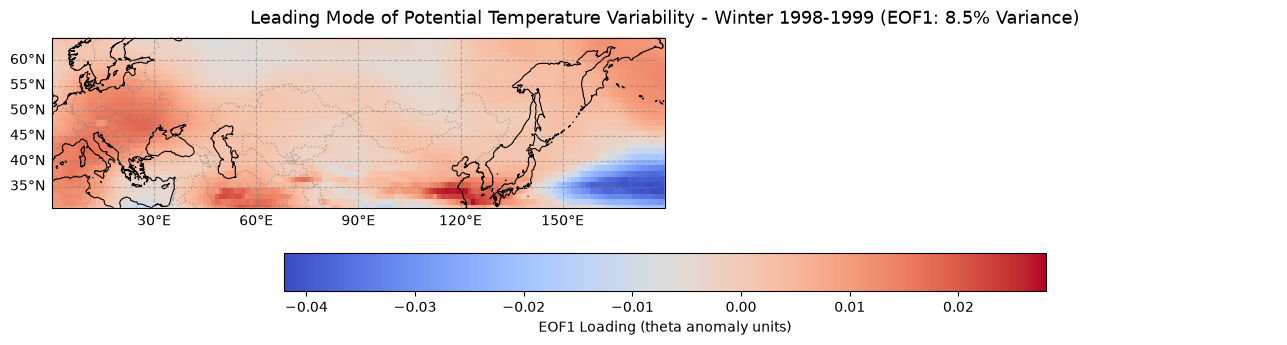

In [55]:
import numpy as np
import matplotlib.pyplot as plt

# Make sure you have the eofs library installed: pip install eofs
from eofs.standard import Eof

# 1. Collect trimmed theta fields (latitudes 30° to 65°) across the winter season
months = ["199812", "199901", "199902"]
theta_list = []
theta_lats, theta_lons = None, None
lat_mask = None

for m in months:
    theta_path = f"../data_excerpt/theta/theta2pvu_{m}.grib"
    _, _, times, _ = read(theta_path, NAMES["theta"])
    
    if theta_lats is None:
        theta_lats, theta_lons, _, _ = read(theta_path, NAMES["theta"], times[0])
        lat_mask = (theta_lats >= 30) & (theta_lats <= 65)
        trimmed_theta_lats = theta_lats[lat_mask]
        
    for t in times:
        _, _, _, fields = read(theta_path, NAMES["theta"], t)
        theta_key = list(fields.keys())[0]
        theta_data = fields[theta_key]
        theta_list.append(theta_data[lat_mask, :])

theta_arr = np.array(theta_list)  # Shape: (time_steps, trimmed_lats, lons)

# 2. Prepare Latitude Weights for Spherical Grid
# Weights are proportional to the square root of the cosine of latitude
lat_rad = np.deg2rad(trimmed_theta_lats)
weights = np.sqrt(np.cos(lat_rad))
# Broadcast weights across the longitude dimension: shape (trimmed_lats, lons)
weights_2d = np.tile(weights[:, np.newaxis], (1, theta_arr.shape[2]))

# 3. Initialize the EOF Solver
# Note: eofs expects input shape of (time, lat, lon)
solver = Eof(theta_arr, weights=weights_2d)

# Retrieve the leading EOF (EOF1) spatial pattern and its Principal Component (PC1)
eof1 = solver.eofs(neofs=1)[0]       # Shape: (trimmed_lats, lons)
pc1 = solver.pcs(npcs=1)[:, 0]        # Shape: (time_steps,)
variance_fractions = solver.varianceFraction()

print(f"Variance explained by EOF1: {variance_fractions[0]*100:.2f}%")
print(f"Variance explained by EOF2: {variance_fractions[1]*100:.2f}%")

# 4. Plot EOF1 Spatial Pattern using Cartopy
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    from cartopy.util import add_cyclic_point
    HAVE_CARTOPY = True
except ImportError:
    HAVE_CARTOPY = False

plt.figure(figsize=(14, 3.3))

if HAVE_CARTOPY:
    ax = plt.axes(projection=ccrs.PlateCarree())
    
    # Add cyclic point to close the Pacific/Atlantic seam smoothly
    eof_cyclic, lons_cyclic = add_cyclic_point(eof1, coord=theta_lons, axis=1)
    lat_2d, lon_2d = np.meshgrid(trimmed_theta_lats, lons_cyclic, indexing='ij')
    
    im = ax.pcolormesh(
        lon_2d, lat_2d, eof_cyclic,
        transform=ccrs.PlateCarree(),
        cmap="coolwarm",
        shading="auto"
    )
    
    ax.set_xlim(lons_cyclic.min(), lons_cyclic.max())
    ax.set_ylim(trimmed_theta_lats.min(), trimmed_lats.max())
    
    center_lat_rad = np.deg2rad(np.mean(trimmed_theta_lats))
    ax.set_aspect(1.0 / np.cos(center_lat_rad))
    
    ax.coastlines(resolution="50m", color="black", linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linestyle=":", edgecolor="gray", alpha=0.5)
    
    gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False, color="gray", alpha=0.5, linestyle="--")
    gl.top_labels = False
    gl.right_labels = False
    
    title_suffix = f" (EOF1: {variance_fractions[0]*100:.1f}% Variance)"
else:
    im = plt.imshow(eof1, origin="lower", cmap="coolwarm", aspect="auto")
    title_suffix = f" (EOF1)"

plt.colorbar(im, label="EOF1 Loading (theta anomaly units)", orientation="horizontal", pad=0.18, shrink=0.6)
plt.title(f"Leading Mode of Potential Temperature Variability - Winter 1998-1999{title_suffix}", fontsize=13, pad=10)

plt.tight_layout()
plt.show()

Number of EOF modes needed for >= 90% cumulative variance: 118
Actual cumulative variance achieved: 90.07%


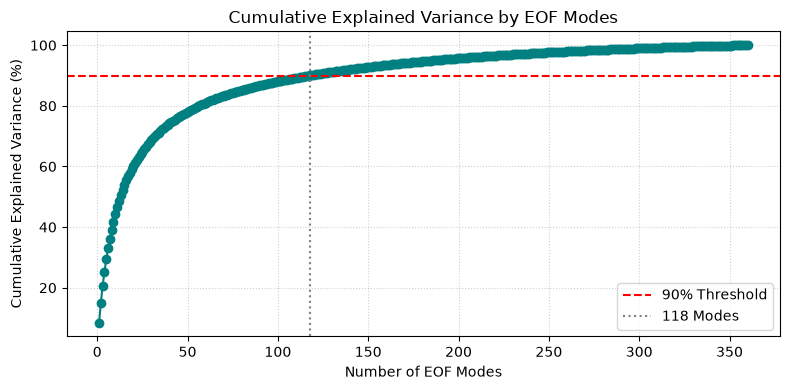

In [56]:
# 1. Get variance fractions for all available modes
variance_fractions = solver.varianceFraction()

# 2. Compute the cumulative sum of variance fractions
cumulative_variance = np.cumsum(variance_fractions)

# 3. Find the first index where cumulative variance crosses 90% (0.90)
# np.argmax finds the first True condition; add 1 because Python is 0-indexed
num_modes_90 = np.argmax(cumulative_variance >= 0.90) + 1
actual_variance_90 = cumulative_variance[num_modes_90 - 1] * 100

print(f"Number of EOF modes needed for >= 90% cumulative variance: {num_modes_90}")
print(f"Actual cumulative variance achieved: {actual_variance_90:.2f}%")

# Optional: Quick plot of cumulative variance to visualize the curve
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance * 100, marker='o', linestyle='-', color='teal')
plt.axhline(90, color='red', linestyle='--', label='90% Threshold')
plt.axvline(num_modes_90, color='gray', linestyle=':', label=f'{num_modes_90} Modes')
plt.title("Cumulative Explained Variance by EOF Modes", fontsize=12)
plt.xlabel("Number of EOF Modes", fontsize=10)
plt.ylabel("Cumulative Explained Variance (%)", fontsize=10)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

Original shape: (360, 31, 320)
Filtered reconstruction shape: (360, 31, 320)


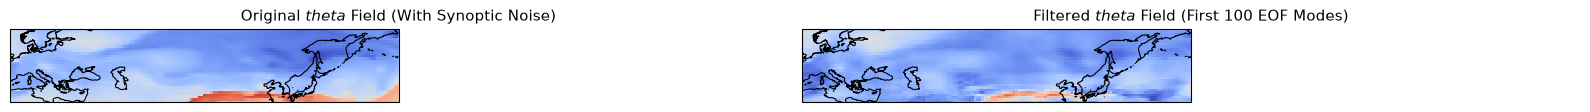

In [98]:
# 1. Reconstruct the theta field using only the first 100 EOF modes
# neofs=5 filters out high-frequency noise and keeps large-scale patterns
reconstructed_theta = solver.reconstructedField(neofs=100)

print(f"Original shape: {theta_arr.shape}")
print(f"Filtered reconstruction shape: {reconstructed_theta.shape}")

# 2. Quick comparison: Look at a single time step (e.g., index 0)
# Before vs After noise filtering
time_idx = 0

fig, axes = plt.subplots(1, 2, figsize=(16, 4), subplot_kw={'projection': ccrs.PlateCarree() if 'ccrs' in globals() else None})

# Helper for plotting quickly
for ax, data_slice, title in zip(axes, [theta_arr[time_idx], reconstructed_theta[time_idx]], 
                                   ["Original $theta$ Field (With Synoptic Noise)", "Filtered $theta$ Field (First 100 EOF Modes)"]):
    if 'ccrs' in globals():
        theta_cyclic, lons_cyclic = add_cyclic_point(data_slice, coord=theta_lons, axis=1)
        lat_2d, lon_2d = np.meshgrid(trimmed_theta_lats, lons_cyclic, indexing='ij')
        im = ax.pcolormesh(lon_2d, lat_2d, theta_cyclic, transform=ccrs.PlateCarree(), cmap="coolwarm", shading="auto")
        ax.set_xlim(lons_cyclic.min(), lons_cyclic.max())
        ax.set_ylim(trimmed_theta_lats.min(), trimmed_lats.max())
        ax.coastlines(resolution="50m", color="black", linewidth=0.8)
    else:
        im = ax.imshow(data_slice, origin="lower", cmap="coolwarm", aspect="auto")
    
    ax.set_title(title, fontsize=11)

plt.tight_layout()
plt.show()

# TESTING noise-reduced theta below

In [76]:
import numpy as np

def detect_blocking_events(times, lats, lons, central_lats, theta_loader_func, min_persistent_days=5):
    """
    Scans through time steps, computes B index, identifies LIB and SB, 
    and detects persistent Sector Blocking Episodes (SBE).
    
    Parameters:
    - times: List of datetime objects for each time step.
    - lats: 1D numpy array of latitudes.
    - lons: 1D numpy array of longitudes.
    - central_lats: Dictionary mapping longitude to phi_c.
    - theta_loader_func: A function(t) that returns the theta field for a given time t.
    - min_persistent_days: Minimum number of consecutive time steps/days required for SBE (default 5).
    
    Returns:
    - sbe_events: List of dictionaries detailing detected blocking episodes (longitude, start time, duration).
    """
    target_lons = np.arange(0, 360, 5)
    lib_matrix = []  # Will store boolean matrix of shape (time_steps, len(target_lons))
    
    print("Step 1: Computing LIB across all time steps...")
    for t in times:
        theta_field = theta_loader_func(t)
        _, b_vals = compute_B_index(lats, lons, theta_field, central_lats)
        
        # LIB occurs when B > 0
        lib_vals = b_vals > 0
        lib_matrix.append(lib_vals)
        
    lib_matrix = np.array(lib_matrix) # Shape: (T, 72 longitudes)
    num_times, num_lons = lib_matrix.shape
    
    print("Step 2: Evaluating Sector Blocking (SB) criteria...")
    # SB requires LIB at 3 consecutive points within a 45-degree sector (9 grid points)
    sb_matrix = np.zeros((num_times, num_lons), dtype=bool)
    
    for t_idx in range(num_times):
        for lon_idx in range(num_lons):
            # Define a 45-degree sector centered at lon_idx (9 points total for 5-deg spacing)
            half_window = 4  # 4 points left, central point, 4 points right = 9 points (45 deg)
            sector_indices = [(lon_idx + j) % num_lons for j in range(-half_window, half_window + 1)]
            
            sector_lib = lib_matrix[t_idx, sector_indices]
            
            # Check if there are at least 3 consecutive True values in this sector
            has_three_consecutive = False
            consecutive_count = 0
            for val in sector_lib:
                if val:
                    consecutive_count += 1
                    if consecutive_count >= 3:
                        has_three_consecutive = True
                        break
                else:
                    consecutive_count = 0
                    
            sb_matrix[t_idx, lon_idx] = has_three_consecutive

    print("Step 3: Evaluating Sector Blocking Episodes (SBE) via temporal persistence...")
    sbe_events = []
    
    # Scan each longitude time-series for contiguous blocks of True values >= min_persistent_days
    for lon_idx, lon in enumerate(target_lons):
        sb_series = sb_matrix[:, lon_idx]
        
        in_episode = False
        start_idx = 0
        
        for t_idx in range(num_times):
            if sb_series[t_idx] and not in_episode:
                in_episode = True
                start_idx = t_idx
            elif not sb_series[t_idx] and in_episode:
                in_episode = False
                duration = t_idx - start_idx
                if duration >= min_persistent_days:
                    sbe_events.append({
                        "longitude": lon,
                        "central_latitude": get_phi_c(lon, central_lats, lons),
                        "start_time": times[start_idx],
                        "end_time": times[t_idx - 1],
                        "duration_steps": duration
                    })
        # Handle edge case if episode reaches the end of the array
        if in_episode:
            duration = num_times - start_idx
            if duration >= min_persistent_days:
                sbe_events.append({
                    "longitude": lon,
                    "central_latitude": get_phi_c(lon, central_lats, lons),
                    "start_time": times[start_idx],
                    "end_time": times[-1],
                    "duration_steps": duration
                })
                
    return sbe_events

In [62]:
import numpy as np
from scipy.ndimage import uniform_filter1d

def compute_central_latitudes(lats, lons, u_timeseries, v_timeseries):
    """
    Computes the optimal central latitude (phi_c) for each longitude based on 
    the maximum of smoothed transient eddy kinetic energy (EKE).
    
    Parameters:
    - lats: 1D numpy array of latitudes
    - lons: 1D numpy array of longitudes
    - u_timeseries: 3D numpy array of shape (time, lat, lon) for u-wind
    - v_timeseries: 3D numpy array of shape (time, lat, lon) for v-wind
    
    Returns:
    - central_lats: dictionary mapping each longitude value to its central latitude
    """
    # 1. Compute transient anomalies by removing the time mean (simple high-pass approximation)
    u_mean = np.nanmean(u_timeseries, axis=0, keepdims=True)
    v_mean = np.nanmean(v_timeseries, axis=0, keepdims=True)
    
    u_prime = u_timeseries - u_mean
    v_prime = v_timeseries - v_mean
    
    # 2. Compute Eddy Kinetic Energy (EKE) at each time step, then average over time
    eke = 0.5 * (u_prime**2 + v_prime**2)
    mean_eke = np.nanmean(eke, axis=0) # Shape: (len(lats), len(lons))
    
    central_lats = {}
    
    # 3. Find the latitude of maximum EKE for every longitude
    for lon_idx, lon in enumerate(lons):
        eke_profile = mean_eke[:, lon_idx]
        
        # Smooth the latitude profile to remove local noise (using a window of 5 grid points)
        smoothed_eke = uniform_filter1d(eke_profile, size=5, mode='reflect')
        
        # Optional: restrict search window to extratropics (e.g., latitudes > 20)
        # to prevent tropical noise from skewing the storm track detection.
        valid_mask = (lats >= 20) & (lats <= 80)
        if np.any(valid_mask):
            search_eke = np.where(valid_mask, smoothed_eke, -np.inf)
            max_idx = np.argmax(search_eke)
        else:
            max_idx = np.argmax(smoothed_eke)
            
        central_lats[lon] = lats[max_idx]
        
    return central_lats

# TODO: Consider using linear interpolation instead of nearest grid point
def get_phi_c(target_lon, central_lats, lons):
    """Finds the central latitude for a given target longitude by finding the nearest grid point."""
    # Handle wrap-around or negative longitudes if necessary
    target_lon = target_lon % 360
    
    # Find the closest longitude in the actual lons array
    closest_lon = lons[np.abs(lons - target_lon).argmin()]
    return central_lats.get(closest_lon, "N/A")

# get available times in the current grib
# If calling read without a time returns times as the 3rd element:
_, _, times, _ = read(theta_path, NAMES["theta"])

# Load the grid using the first available time
first_time = times[0]
lats, lons, _, fields = read(theta_path, NAMES["theta"], first_time)

# 1. Gather time series data for u and v across all time steps
u_list, v_list = [], []

for t in times:
    _, _, _, fields = read(uv_path, NAMES["uv"], t)
    u_list.append(fields["u"]) 
    v_list.append(fields["v"])

u_timeseries = np.array(u_list) # Shape: (time, lat, lon)
v_timeseries = np.array(v_list)

# 2. Compute central latitudes dynamically
central_lats = compute_central_latitudes(lats, lons, u_timeseries, v_timeseries)

print("Sample phi_c values every 5 degrees of longitude:")
for lon in range(0, 360, 5):
    val = get_phi_c(lon, central_lats, lons)
    val_str = f"{val:.4f}°N" if isinstance(val, (int, float, np.number)) else val
    print(f"Longitude {lon}°: Central Latitude = {val_str}")

Sample phi_c values every 5 degrees of longitude:
Longitude 0°: Central Latitude = 57.7566°N
Longitude 5°: Central Latitude = 45.4203°N
Longitude 10°: Central Latitude = 46.5418°N
Longitude 15°: Central Latitude = 47.6632°N
Longitude 20°: Central Latitude = 48.7847°N
Longitude 25°: Central Latitude = 49.9062°N
Longitude 30°: Central Latitude = 52.1492°N
Longitude 35°: Central Latitude = 51.0277°N
Longitude 40°: Central Latitude = 61.1210°N
Longitude 45°: Central Latitude = 71.2141°N
Longitude 50°: Central Latitude = 72.3356°N
Longitude 55°: Central Latitude = 72.3356°N
Longitude 60°: Central Latitude = 73.4570°N
Longitude 65°: Central Latitude = 74.5784°N
Longitude 70°: Central Latitude = 74.5784°N
Longitude 75°: Central Latitude = 73.4570°N
Longitude 80°: Central Latitude = 73.4570°N
Longitude 85°: Central Latitude = 73.4570°N
Longitude 90°: Central Latitude = 72.3356°N
Longitude 95°: Central Latitude = 71.2141°N
Longitude 100°: Central Latitude = 71.2141°N
Longitude 105°: Central Lat

In [77]:
import numpy as np

def compute_B_index(lats, lons, theta_field, central_lats):
    """
    Computes the B index for every 5 degrees of longitude.
    
    Parameters:
    - lats: 1D numpy array of latitudes
    - lons: 1D numpy array of longitudes
    - theta_field: 2D numpy array of shape (len(lats), len(lons)) representing theta on 2PVU
    - central_lats: dictionary or array mapping each longitude to its central latitude phi_c
    
    Returns:
    - b_indices: 1D numpy array of B values corresponding to the target longitudes
    """
    b_indices = []
    
    # Target longitudes every 5 degrees
    target_lons = np.arange(0, 360, 5)
    
    for lon in target_lons:
        # Find the index for this longitude
        lon_idx = np.abs(lons - lon).argmin()
        phi_c = central_lats.get(lon, 45.0)  # Default/example central latitude
        # phi_c = central_lats
        
        # Define the poleward and equatorward 15-degree bands
        # Equatorward band: [phi_c - 15, phi_c]
        # Poleward band: [phi_c, phi_c + 15]
        eq_mask = (lats >= phi_c - 15) & (lats < phi_c)
        pole_mask = (lats > phi_c) & (lats <= phi_c + 15)
        
        # Extract theta column at this longitude
        theta_col = theta_field[:, lon_idx]
        
        # Calculate averages for the bands
        theta_eq = np.nanmean(theta_col[eq_mask])
        theta_pole = np.nanmean(theta_col[pole_mask])
        
        # B index is the difference (Poleward average - Equatorward average)
        b_val = theta_pole - theta_eq
        b_indices.append(b_val)
        
    return target_lons, np.array(b_indices)

In [87]:
# Define a quick wrapper function to fetch the theta field for a given time 't'
def theta_loader(t):
    # Dynamically grab the correct month file for each timestamp
    month_str = t.strftime("%Y%m")
    theta_path = f"../data_excerpt/theta/theta2pvu_{month_str}.grib"
    
    _, _, _, fields = read(theta_path, NAMES["theta"], t)
    theta_key = list(fields.keys())[0]
    return fields[theta_key]

# Run the detector (adjust min_persistent_days if your data is 4x daily vs daily)
# Note: If you have 4 time steps per day, 5 days = 20 time steps.
min_steps = 4 * 4 # 5 days * 4 records/day = 20 steps (shortened to 16 to grab some at least 1)
blocking_episodes = detect_blocking_events(
    times, lats, lons, central_lats, theta_loader, min_persistent_days=min_steps
)

print(f"\nFound {len(blocking_episodes)} persistent Sector Blocking Episodes (SBE):")
for event in blocking_episodes[:10]:  # Print first 10 results
    print(
        f"Longitude: {event['longitude']}°E | "
        f"Latitude (~{event['central_latitude']}°N) | "
        f"From {event['start_time']} to {event['end_time']} "
        f"({event['duration_steps']} steps)"
    )

Step 1: Computing LIB across all time steps...
Step 2: Evaluating Sector Blocking (SB) criteria...
Step 3: Evaluating Sector Blocking Episodes (SBE) via temporal persistence...

Found 1 persistent Sector Blocking Episodes (SBE):
Longitude: 355°E | Latitude (~57.7565686241836°N) | From 1999-02-01 00:00:00 to 1999-02-04 18:00:00 (16 steps)


In [99]:
import numpy as np

# 1. Rebuild the master list of all times across the winter season 
# (matching the exact order used when building theta_arr)
all_times_combined = []
for m in ["199812", "199901", "199902"]:
    theta_path = f"../data_excerpt/theta/theta2pvu_{m}.grib"
    _, _, times, _ = read(theta_path, NAMES["theta"])
    all_times_combined.extend(times)

# 2. Map each timestamp to its index in the reconstructed_theta array
time_to_idx = {t: idx for idx, t in enumerate(all_times_combined)}

# 3. Create a custom loader that pulls from the filtered reconstruction
def filtered_theta_loader(t):
    idx = time_to_idx[t]
    return reconstructed_theta[idx]  # Shape: (trimmed_lats, lons)

# 4. Run the blocking detector using the filtered theta field 
# (Using trimmed_theta_lats for the 30°N–65°N latitudinal band)
min_steps = 5 * 4  # 5 days * 4 records/day = 20 steps
filtered_blocking_episodes = detect_blocking_events(
    times=all_times_combined,
    lats=trimmed_theta_lats,
    lons=theta_lons,
    central_lats=central_lats,
    theta_loader_func=filtered_theta_loader,
    min_persistent_days=min_steps
)

# 5. Summary of Results
print(f"\n--- Filtered Blocking Detection Results ---")
print(f"Total persistent SBE events found: {len(filtered_blocking_episodes)}")
for event in filtered_blocking_episodes[:10]:  # Print first 10
    print(
        f"Longitude: {event['longitude']}°E | "
        f"Latitude (~{event['central_latitude']}°N) | "
        f"From {event['start_time']} to {event['end_time']} "
        f"({event['duration_steps']} steps)"
    )

Step 1: Computing LIB across all time steps...


/tmp/ipykernel_224483/460356298.py:38: RuntimeWarning: Mean of empty slice
  theta_pole = np.nanmean(theta_col[pole_mask])


Step 2: Evaluating Sector Blocking (SB) criteria...
Step 3: Evaluating Sector Blocking Episodes (SBE) via temporal persistence...

--- Filtered Blocking Detection Results ---
Total persistent SBE events found: 301
Longitude: 0°E | Latitude (~57.7565686241836°N) | From 1998-12-23 18:00:00 to 1998-12-28 18:00:00 (21 steps)
Longitude: 0°E | Latitude (~57.7565686241836°N) | From 1999-01-19 06:00:00 to 1999-02-05 00:00:00 (68 steps)
Longitude: 0°E | Latitude (~57.7565686241836°N) | From 1999-02-10 00:00:00 to 1999-02-20 12:00:00 (43 steps)
Longitude: 5°E | Latitude (~45.42027862654827°N) | From 1999-01-19 06:00:00 to 1999-01-26 06:00:00 (29 steps)
Longitude: 5°E | Latitude (~45.42027862654827°N) | From 1999-01-29 06:00:00 to 1999-02-05 00:00:00 (28 steps)
Longitude: 5°E | Latitude (~45.42027862654827°N) | From 1999-02-10 06:00:00 to 1999-02-20 06:00:00 (41 steps)
Longitude: 10°E | Latitude (~46.54176268340568°N) | From 1998-12-11 06:00:00 to 1998-12-19 12:00:00 (34 steps)
Longitude: 10°E | 

## Plotting Detected Active blocking episodes and creating GIFs from them

In [110]:
import datetime
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import imageio.v2 as imageio

# Check for Cartopy
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    from cartopy.util import add_cyclic_point
    HAVE_CARTOPY = True
except ImportError:
    HAVE_CARTOPY = False

# Ensure we have at least one detected event
if len(blocking_episodes) > 0:
    # Pick the first detected event
    event = blocking_episodes[0]
    
    target_lon = event['longitude']
    target_lat = event['central_latitude']
    start_str = event['start_time'].strftime('%Y%m%d')
    
    print(f"Visualizing Event at Longitude: {target_lon}°E, Latitude: ~{target_lat}°N")
    
    # 1. Setup frame directory
    frame_dir = Path("./blocking_frames")
    frame_dir.mkdir(parents=True, exist_ok=True)
    
    for old_frame in frame_dir.glob("frame_*.png"):
            old_frame.unlink()
    
    # Define window: Start - 5 day to End + 5 day
    buffer_start = event['start_time'] - datetime.timedelta(days=5)
    buffer_end = event['end_time'] + datetime.timedelta(days=5)
    
    # Filter times within this window from your master timeline
    window_times = [t for t in all_times_combined if buffer_start <= t <= buffer_end]
    
    # 2. Loop through each time step, plot, and save as a frame
    for idx, t in enumerate(window_times):
        month_str = t.strftime("%Y%m")
        theta_path = f"../data_excerpt/theta/theta2pvu_{month_str}.grib"
        uv_path = f"../data_excerpt/uv/uv300_{month_str}.grib"
        
        # Load FULL global grid for theta
        full_lats, full_lons, _, theta_fields = read(theta_path, NAMES["theta"], t)
        theta_key = list(theta_fields.keys())[0]
        theta_global = theta_fields[theta_key]
        
        # Load FULL global grid for u and v winds
        uv_lats, uv_lons, _, uv_fields = read(uv_path, NAMES["uv"], t)
        uv_keys = list(uv_fields.keys())
        u_global = uv_fields[uv_keys[0]]
        v_global = uv_fields[uv_keys[1]]
        
        fig = plt.figure(figsize=(14, 7))
        
        if HAVE_CARTOPY:
            ax = plt.axes(projection=ccrs.PlateCarree())
            
            # Add cyclic points to theta and wind components to avoid seams
            theta_cyclic, lons_cyclic = add_cyclic_point(theta_global, coord=full_lons, axis=1)
            u_cyclic, _ = add_cyclic_point(u_global, coord=uv_lons, axis=1)
            v_cyclic, _ = add_cyclic_point(v_global, coord=uv_lons, axis=1)
            
            lat_2d, lon_2d = np.meshgrid(full_lats, lons_cyclic, indexing='ij')
            
            # Plot theta background
            im = ax.pcolormesh(
                lon_2d, lat_2d, theta_cyclic,
                transform=ccrs.PlateCarree(),
                cmap="coolwarm",
                shading="auto"
            )
            ax.set_global()
            ax.coastlines(resolution="50m", color="black", linewidth=0.7)
            ax.add_feature(cfeature.BORDERS, linestyle=":", edgecolor="gray", alpha=0.5)
            ax.add_feature(cfeature.LAND, facecolor="lightgray", alpha=0.3)
            
            # --- wind vectors (Enhanced Scaling & Styling) ---------------------
            stride = 6  # Optimized for global view
            s = slice(None, None, stride)
            qkw = dict(
                color="black", edgecolor="white", linewidth=0.4,
                scale=1500, width=0.0018, headwidth=4, 
                transform=ccrs.PlateCarree()
            )
            
            q = ax.quiver(lon_2d[s, s], lat_2d[s, s], u_cyclic[s, s], v_cyclic[s, s], **qkw)
            ax.quiverkey(q, 0.9, 1.03, 50, "50 m/s", labelpos="E", coordinates="axes",
                         fontproperties={"size": 8})
            # ------------------------------------------------------------------
            
            # Circle/Highlight the Region of Interest (ROI)
            if t < event['start_time'] or t > event['end_time']:
                ax.plot(
                    target_lon, target_lat,
                    marker='o', markersize=20, markerfacecolor='none', 
                    markeredgecolor='lime', markeredgewidth=2.5,
                    transform=ccrs.PlateCarree(),
                    label=f"Blocked Region ({target_lon}°E, ~{target_lat}°N)"
                )
            else:
                ax.plot(
                    target_lon, target_lat,
                    marker='o', markersize=20, markerfacecolor='none', 
                    markeredgecolor='red', markeredgewidth=2.5,
                    transform=ccrs.PlateCarree(),
                    label=f"Blocked Region ({target_lon}°E, ~{target_lat}°N)"
                )
            
            gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False, color="gray", alpha=0.4, linestyle="--")
            gl.top_labels = False
            gl.right_labels = False
            plt.legend(loc='upper right', framealpha=0.8)
            wind_str = ""
        else:
            im = plt.imshow(theta_global, origin="lower", cmap="coolwarm", aspect="auto")
            plt.axvline(target_lon, color='lime', linestyle='--', label="Blocked Longitude")
            wind_str = ""
        
        # Determine status label relative to the event
        if t < event['start_time']:
            status = "PRE-BLOCK (5 Days Prior)"
        elif t > event['end_time']:
            status = "POST-BLOCK (5 Days After)"
        else:
            status = "ACTIVE BLOCKING EPISODE"
            
        plt.colorbar(im, label="Potential Temperature ($\theta$ at 2 PVU)", orientation="horizontal", pad=0.08, shrink=0.7)
        plt.title(f"Global Theta & Blocking Monitor | Time: {t.strftime('%Y-%m-%d %H:%M')} UTC\nStatus: {status}{wind_str}", fontsize=13, pad=12)
        
        plt.tight_layout()
        
        # Save frame with zero-padded index to maintain correct chronological sort order
        frame_filename = frame_dir / f"frame_{idx:03d}.png"
        plt.savefig(frame_filename, dpi=150)
        plt.close(fig) # Close figure to free memory

    print(f"Successfully saved {len(window_times)} frames to {frame_dir}")

    frame_files = sorted(frame_dir.glob("frame_*.png"))
    
    valid_images = []

    for f in frame_files:
        # Check if file is empty (0 bytes)
        if f.stat().st_size == 0:
            print(f"Skipping empty frame: {f.name}")
            continue
        
        try:
            img = imageio.imread(str(f))
            valid_images.append(img)
        except Exception as e:
            print(f"Skipping corrupted frame {f.name}: {e}")

    if valid_images:
        # Construct GIF path safely using strings
        date_str = event['start_time'].strftime('%Y%m%d')
        lat_str = f"lat{int(target_lat)}"
        lng_str = f"lng{int(target_lon)}"
        gif_path = f"./blocking_episode_{date_str}_{lat_str}_{lng_str}.gif"
        
        imageio.mimsave(gif_path, valid_images, fps=10)
        print(f"\nGIF successfully saved to {gif_path} with {len(valid_images)} frames")
    else:
        print("\nNo valid frames were found to create the GIF. Check your frame generation loop above.")

Visualizing Event at Longitude: 355°E, Latitude: ~57.7565686241836°N
Successfully saved 56 frames to blocking_frames

GIF successfully saved to ./blocking_episode_19990201_lat57_lng355.gif with 56 frames


### Check to see if the blocking episode discovered using the recomputed B values matches any that were discovered from the filtered episodes

In [100]:
print(blocking_episodes in filtered_blocking_episodes)

False


It was not :( This seems to suggest that the filtered theta (using only the top 100 EOF modes) is possibly insufficient to detect blocking events successfully 

In [ ]:
import datetime
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import imageio.v2 as imageio  # Using v2 to avoid deprecation warnings with imread/mimsave

# Check for Cartopy
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    from cartopy.util import add_cyclic_point
    HAVE_CARTOPY = True
except ImportError:
    HAVE_CARTOPY = False

# Ensure we have at least one detected event
if len(filtered_blocking_episodes) > 0:
    for event in filtered_blocking_episodes[:10]: # only take the first 10 filtered blocking episodes - there are a lot more than "regular" blocking
        
        target_lon = event['longitude']
        target_lat = event['central_latitude']
        start_str = event['start_time'].strftime('%Y%m%d')
        
        print(f"Visualizing Event at Longitude: {target_lon}°E, Latitude: ~{target_lat}°N")
        
        # 1. Setup frame directory
        frame_dir = Path("./blocking_frames")
        frame_dir.mkdir(parents=True, exist_ok=True)

        for old_frame in frame_dir.glob("frame_*.png"):
            old_frame.unlink()
        
        # Define window: Start - 5 day to End + 5 day
        buffer_start = event['start_time'] - datetime.timedelta(days=5)
        buffer_end = event['end_time'] + datetime.timedelta(days=5)
        
        # Filter times within this window from your master timeline
        window_times = [t for t in all_times_combined if buffer_start <= t <= buffer_end]
        
        # 2. Loop through each time step, plot, and save as a frame
        for idx, t in enumerate(window_times):
            month_str = t.strftime("%Y%m")
            theta_path = f"../data_excerpt/theta/theta2pvu_{month_str}.grib"
            uv_path = f"../data_excerpt/uv/uv300_{month_str}.grib"
            
            # Load FULL global grid for theta
            full_lats, full_lons, _, theta_fields = read(theta_path, NAMES["theta"], t)
            theta_key = list(theta_fields.keys())[0]
            theta_global = theta_fields[theta_key]
            
            # Load FULL global grid for u and v winds
            uv_lats, uv_lons, _, uv_fields = read(uv_path, NAMES["uv"], t)
            uv_keys = list(uv_fields.keys())
            u_global = uv_fields[uv_keys[0]]
            v_global = uv_fields[uv_keys[1]]
            
            fig = plt.figure(figsize=(14, 7))
            
            if HAVE_CARTOPY:
                ax = plt.axes(projection=ccrs.PlateCarree())
                
                # Add cyclic points to theta and wind components to avoid seams
                theta_cyclic, lons_cyclic = add_cyclic_point(theta_global, coord=full_lons, axis=1)
                u_cyclic, _ = add_cyclic_point(u_global, coord=uv_lons, axis=1)
                v_cyclic, _ = add_cyclic_point(v_global, coord=uv_lons, axis=1)
                
                lat_2d, lon_2d = np.meshgrid(full_lats, lons_cyclic, indexing='ij')
                
                # Plot theta background
                im = ax.pcolormesh(
                    lon_2d, lat_2d, theta_cyclic,
                    transform=ccrs.PlateCarree(),
                    cmap="coolwarm",
                    shading="auto"
                )
                ax.set_global()
                ax.coastlines(resolution="50m", color="black", linewidth=0.7)
                ax.add_feature(cfeature.BORDERS, linestyle=":", edgecolor="gray", alpha=0.5)
                ax.add_feature(cfeature.LAND, facecolor="lightgray", alpha=0.3)
                
                # --- wind vectors (Enhanced Scaling & Styling) ---------------------
                stride = 6  # Optimized for global view
                s = slice(None, None, stride)
                qkw = dict(
                    color="black", edgecolor="white", linewidth=0.4,
                    scale=1500, width=0.0018, headwidth=4, 
                    transform=ccrs.PlateCarree()
                )
                
                q = ax.quiver(lon_2d[s, s], lat_2d[s, s], u_cyclic[s, s], v_cyclic[s, s], **qkw)
                ax.quiverkey(q, 0.9, 1.03, 50, "50 m/s", labelpos="E", coordinates="axes",
                            fontproperties={"size": 8})
                # ------------------------------------------------------------------
                
                # Circle/Highlight the Region of Interest (ROI)
                if t < event['start_time'] or t > event['end_time']:
                    ax.plot(
                        target_lon, target_lat,
                        marker='o', markersize=20, markerfacecolor='none', 
                        markeredgecolor='lime', markeredgewidth=2.5,
                        transform=ccrs.PlateCarree(),
                        label=f"Blocked Region ({target_lon}°E, ~{target_lat}°N)"
                    )
                else:
                    ax.plot(
                        target_lon, target_lat,
                        marker='o', markersize=20, markerfacecolor='none', 
                        markeredgecolor='red', markeredgewidth=2.5,
                        transform=ccrs.PlateCarree(),
                        label=f"Blocked Region ({target_lon}°E, ~{target_lat}°N)"
                    )
                
                gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False, color="gray", alpha=0.4, linestyle="--")
                gl.top_labels = False
                gl.right_labels = False
                plt.legend(loc='upper right', framealpha=0.8)
                wind_str = ""
            else:
                im = plt.imshow(theta_global, origin="lower", cmap="coolwarm", aspect="auto")
                plt.axvline(target_lon, color='lime', linestyle='--', label="Blocked Longitude")
                wind_str = ""
            
            # Determine status label relative to the event
            if t < event['start_time']:
                status = "PRE-BLOCK (5 Days Prior)"
            elif t > event['end_time']:
                status = "POST-BLOCK (5 Days After)"
            else:
                status = "ACTIVE BLOCKING EPISODE"
                
            plt.colorbar(im, label="Potential Temperature ($\theta$ at 2 PVU)", orientation="horizontal", pad=0.08, shrink=0.7)
            plt.title(f"Global Theta & Blocking Monitor | Time: {t.strftime('%Y-%m-%d %H:%M')} UTC\nStatus: {status}{wind_str}", fontsize=13, pad=12)
            
            plt.tight_layout()
            
            # Save frame with zero-padded index to maintain correct chronological sort order
            frame_filename = frame_dir / f"frame_{idx:03d}.png"
            plt.savefig(frame_filename, dpi=150)
            plt.close(fig) # Close figure to free memory

        print(f"Successfully saved {len(window_times)} frames to {frame_dir}")

        # 3. Combine frames into an animated GIF
        frame_files = sorted(frame_dir.glob("frame_*.png"))
        if frame_files:
            images = [imageio.imread(str(f)) for f in frame_files]
            
            # Construct GIF path safely using strings
            date_str = event['start_time'].strftime('%Y%m%d')
            lat_str = f"lat{int(target_lat)}"
            lng_str = f"lng{int(target_lon)}"
            gif_path = f"./filtered_theta_blocking_episode_{date_str}_{lat_str}_{lng_str}.gif"
            
            imageio.mimsave(gif_path, images, fps=10)

Visualizing Event at Longitude: 0°E, Latitude: ~57.7565686241836°N
Successfully saved 61 frames to blocking_frames
Visualizing Event at Longitude: 0°E, Latitude: ~57.7565686241836°N
Successfully saved 108 frames to blocking_frames
Visualizing Event at Longitude: 0°E, Latitude: ~57.7565686241836°N
Successfully saved 83 frames to blocking_frames
Visualizing Event at Longitude: 5°E, Latitude: ~45.42027862654827°N
Successfully saved 69 frames to blocking_frames
Visualizing Event at Longitude: 5°E, Latitude: ~45.42027862654827°N
Successfully saved 68 frames to blocking_frames
Visualizing Event at Longitude: 5°E, Latitude: ~45.42027862654827°N
Successfully saved 81 frames to blocking_frames
Visualizing Event at Longitude: 10°E, Latitude: ~46.54176268340568°N
Successfully saved 74 frames to blocking_frames
Visualizing Event at Longitude: 10°E, Latitude: ~46.54176268340568°N
Successfully saved 63 frames to blocking_frames
Visualizing Event at Longitude: 10°E, Latitude: ~46.54176268340568°N
Suc

In [ ]:
import datetime
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import imageio.v2 as imageio

# Check for Cartopy
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    from cartopy.util import add_cyclic_point
    HAVE_CARTOPY = True
except ImportError:
    HAVE_CARTOPY = False

# Ensure we have at least one detected event
if len(blocking_episodes) > 0:
    # Pick the first detected event
    event = blocking_episodes[0]
    
    target_lon = event['longitude']
    target_lat = event['central_latitude']
    start_str = event['start_time'].strftime('%Y%m%d')
    
    print(f"Visualizing Regional Sector for Event at Longitude: {target_lon}°E, Latitude: ~{target_lat}°N")
    
    # 1. Setup frame directory & clear any old frames
    frame_dir = Path("./blocking_frames")
    frame_dir.mkdir(parents=True, exist_ok=True)
    
    for old_frame in frame_dir.glob("frame_*.png"):
        old_frame.unlink()
        
    # Define window: Start - 5 day to End + 5 day
    buffer_start = event['start_time'] - datetime.timedelta(days=5)
    buffer_end = event['end_time'] + datetime.timedelta(days=5)
    
    # Filter times within this window from your master timeline
    window_times = [t for t in all_times_combined if buffer_start <= t <= buffer_end]
    
    # Define regional sector bounding box (e.g., ±35° longitude, ±20° latitude around center)
    lon_margin = 40.0
    lat_margin = 50.0
    
    # Handle longitude wrap-around safely for extent
    min_lon = target_lon - lon_margin
    max_lon = target_lon + lon_margin
    min_lat = max(trimmed_lats.min(), target_lat - lat_margin)
    max_lat = min(trimmed_lats.max(), target_lat + lat_margin)
    
    # 2. Loop through each time step, plot, and save as a frame
    for idx, t in enumerate(window_times):
        month_str = t.strftime("%Y%m")
        theta_path = f"../data_excerpt/theta/theta2pvu_{month_str}.grib"
        uv_path = f"../data_excerpt/uv/uv300_{month_str}.grib"
        
        # Load FULL global grid for theta
        full_lats, full_lons, _, theta_fields = read(theta_path, NAMES["theta"], t)
        theta_key = list(theta_fields.keys())[0]
        theta_global = theta_fields[theta_key]
        
        # Load FULL global grid for u and v winds
        uv_lats, uv_lons, _, uv_fields = read(uv_path, NAMES["uv"], t)
        uv_keys = list(uv_fields.keys())
        u_global = uv_fields[uv_keys[0]]
        v_global = uv_fields[uv_keys[1]]
        
        fig = plt.figure(figsize=(9, 9))  # Square figure works best for centered regional projections
        
        if HAVE_CARTOPY:
            # Use an Orthographic projection centered directly on the blocking event
            # This preserves true regional shape and prevents lat/lon squishing
            proj = ccrs.Orthographic(central_longitude=target_lon, central_latitude=target_lat)
            ax = plt.axes(projection=proj)
            
            # Define regional sector bounding box around the target
            lon_margin = 35.0
            lat_margin = 20.0
            min_lon = target_lon - lon_margin
            max_lon = target_lon + lon_margin
            min_lat = max(trimmed_lats.min(), target_lat - lat_margin)
            max_lat = min(trimmed_lats.max(), target_lat + lat_margin)
            
            # Set extent using PlateCarree coordinates
            ax.set_extent([min_lon, max_lon, min_lat, max_lat], crs=ccrs.PlateCarree())
            
            # Add cyclic points to theta and wind components to avoid seams
            theta_cyclic, lons_cyclic = add_cyclic_point(theta_global, coord=full_lons, axis=1)
            u_cyclic, _ = add_cyclic_point(u_global, coord=uv_lons, axis=1)
            v_cyclic, _ = add_cyclic_point(v_global, coord=uv_lons, axis=1)
            
            lat_2d, lon_2d = np.meshgrid(full_lats, lons_cyclic, indexing='ij')
            
            # Plot theta background
            im = ax.pcolormesh(
                lon_2d, lat_2d, theta_cyclic,
                transform=ccrs.PlateCarree(),
                cmap="coolwarm",
                shading="auto"
            )
            
            ax.coastlines(resolution="50m", color="black", linewidth=0.9)
            ax.add_feature(cfeature.BORDERS, linestyle=":", edgecolor="gray", alpha=0.5)
            ax.add_feature(cfeature.LAND, facecolor="lightgray", alpha=0.3)
            
            # --- wind vectors (Optimized for Regional View) ---------------------
            stride = 2
            s = slice(None, None, stride)
            qkw = dict(
                color="black", edgecolor="white", linewidth=0.4,
                scale=1500, width=0.0022, headwidth=4, 
                transform=ccrs.PlateCarree()
            )
            
            q = ax.quiver(lon_2d[s, s], lat_2d[s, s], u_cyclic[s, s], v_cyclic[s, s], **qkw)
            ax.quiverkey(q, 0.82, 1.03, 50, "50 m/s", labelpos="E", coordinates="axes",
                         fontproperties={"size": 8})
            
            max_wind = np.hypot(u_cyclic, v_cyclic).max()
            wind_str = ""

            # ------------------------------------------------------------------
            
            # Circle/Highlight the Region of Interest (ROI)
            if t < event['start_time'] or t > event['end_time']:
                ax.plot(
                    target_lon, target_lat,
                    marker='o', markersize=20, markerfacecolor='none', 
                    markeredgecolor='lime', markeredgewidth=2.5,
                    transform=ccrs.PlateCarree(),
                    label=f"Blocked Region ({target_lon}°E, ~{target_lat}°N)"
                )
            else:
                ax.plot(
                    target_lon, target_lat,
                    marker='o', markersize=20, markerfacecolor='none', 
                    markeredgecolor='red', markeredgewidth=2.5,
                    transform=ccrs.PlateCarree(),
                    label=f"Blocked Region ({target_lon}°E, ~{target_lat}°N)"
                )
            
            # Gridlines look cleaner in Orthographic when rendered as curved lines or omitted, 
            # but standard gridlines work well with labels
            gl = ax.gridlines(draw_labels=False, color="gray", alpha=0.4, linestyle="--")
            plt.legend(loc='upper right', framealpha=0.8)
        else:
            im = plt.imshow(theta_global, origin="lower", cmap="coolwarm", aspect="auto")
            plt.axvline(target_lon, color='lime', linestyle='--', label="Blocked Longitude")
            wind_str = ""
        
        # Determine status label relative to the event
        if t < event['start_time']:
            status = "PRE-BLOCK (5 Days Prior)"
        elif t > event['end_time']:
            status = "POST-BLOCK (5 Days After)"
        else:
            status = "ACTIVE BLOCKING EPISODE"
            
        plt.colorbar(im, label="Potential Temperature ($\theta$ at 2 PVU)", orientation="horizontal", pad=0.08, shrink=0.7)
        plt.title(f"Regional Blocking Monitor | Lon: {target_lon}°E, Lat: ~{target_lat}°N\nTime: {t.strftime('%Y-%m-%d %H:%M')} UTC | Status: {status}{wind_str}", fontsize=12, pad=12)
        
        plt.tight_layout()
        
        # Save frame with zero-padded index
        frame_filename = frame_dir / f"frame_{idx:03d}.png"
        plt.savefig(frame_filename, dpi=150)
        plt.close(fig)

    print(f"Successfully saved {len(window_times)} regional frames to {frame_dir}")

    # 3. Combine frames into an animated GIF with error handling
    frame_files = sorted(frame_dir.glob("frame_*.png"))
    valid_images = []

    for f in frame_files:
        if f.stat().st_size == 0:
            continue
        try:
            img = imageio.imread(str(f))
            valid_images.append(img)
        except Exception as e:
            print(f"Skipping corrupted frame {f.name}: {e}")

    if valid_images:
        date_str = event['start_time'].strftime('%Y%m%d')
        lat_str = f"lat{int(target_lat)}"
        lng_str = f"lng{int(target_lon)}"
        gif_path = f"./uv_regional_blocking_{date_str}_{lat_str}_{lng_str}.gif"
        
        imageio.mimsave(gif_path, valid_images, fps=5)
        print(f"\nRegional GIF successfully saved to {gif_path} with {len(valid_images)} frames")
    else:
        print("\nNo valid frames found to create the GIF.")

else:
    print("No blocking episodes found to visualize.")

Visualizing Regional Sector for Event at Longitude: 355°E, Latitude: ~57.7565686241836°N
Successfully saved 56 regional frames to blocking_frames

Regional GIF successfully saved to ./regional_blocking_19990201_lat57_lng355.gif with 56 frames


In [122]:
import datetime
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter
import imageio.v2 as imageio

# Check for Cartopy
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    from cartopy.util import add_cyclic_point
    HAVE_CARTOPY = True
except ImportError:
    HAVE_CARTOPY = False

if len(blocking_episodes) > 0:
    event = blocking_episodes[0]
    
    target_lon = event['longitude']
    target_lat = event['central_latitude']
    
    print(f"Visualizing Streamlines of Smoothed Theta Gradient | Lon: {target_lon}°E, Lat: ~{target_lat}°N")
    
    # 1. Setup frame directory & clear old frames
    frame_dir = Path("./blocking_frames")
    frame_dir.mkdir(parents=True, exist_ok=True)
    for old_frame in frame_dir.glob("frame_*.png"):
        old_frame.unlink()
        
    # Define window: Start - 5 day to End + 5 day
    buffer_start = event['start_time'] - datetime.timedelta(days=5)
    buffer_end = event['end_time'] + datetime.timedelta(days=5)
    window_times = [t for t in all_times_combined if buffer_start <= t <= buffer_end]
    
    # Regional sector bounding box
    lon_margin = 35.0
    lat_margin = 40.0
    min_lon = target_lon - lon_margin
    max_lon = target_lon + lon_margin
    min_lat = max(trimmed_lats.min(), target_lat - lat_margin)
    max_lat = min(trimmed_lats.max(), target_lat + lat_margin)
    
    R = 6371000.0
    
    # 2. Loop through time steps with smoothed gradients and streamlines
    for idx, t in enumerate(window_times):
        month_str = t.strftime("%Y%m")
        theta_path = f"../data_excerpt/theta/theta2pvu_{month_str}.grib"
        
        full_lats, full_lons, _, theta_fields = read(theta_path, NAMES["theta"], t)
        theta_key = list(theta_fields.keys())[0]
        theta_global = theta_fields[theta_key]
        
        # Apply spatial smoothing to suppress synoptic noise
        theta_smooth = gaussian_filter(theta_global, sigma=2.0)
        
        fig = plt.figure(figsize=(9, 9))
        
        if HAVE_CARTOPY:
            proj = ccrs.Orthographic(central_longitude=target_lon, central_latitude=target_lat)
            ax = plt.axes(projection=proj)
            ax.set_extent([min_lon, max_lon, min_lat, max_lat], crs=ccrs.PlateCarree())
            
            # Add cyclic point to smoothed theta field
            theta_cyclic, lons_cyclic = add_cyclic_point(theta_smooth, coord=full_lons, axis=1)
            lat_2d, lon_2d = np.meshgrid(full_lats, lons_cyclic, indexing='ij')
            
            # Spherical Gradient Computation
            lat_rad = np.deg2rad(full_lats)
            lon_c_rad = np.deg2rad(lons_cyclic)
            dlat_rad = np.mean(np.diff(lat_rad))
            dlon_rad = np.mean(np.diff(lon_c_rad))
            lat_2d_rad, _ = np.meshgrid(lat_rad, lon_c_rad, indexing='ij')
            
            grad_lat, grad_lon = np.gradient(theta_cyclic, axis=(0, 1))
            dy = R * dlat_rad
            dx = R * np.cos(lat_2d_rad) * dlon_rad
            
            d_theta_dy = (grad_lat / dy) * 100000.0  # K per 100 km
            d_theta_dx = (grad_lon / dx) * 100000.0
            
            # ** FIX: Clip extreme gradient spikes to stabilize streamline rendering **
            mag = np.hypot(d_theta_dx, d_theta_dy)
            max_cap = 30.0  # Cap gradients above 30 K/100km to prevent rogue stretching
            scale_factor = np.minimum(1.0, max_cap / (mag + 1e-5))
            d_theta_dx_capped = d_theta_dx * scale_factor
            d_theta_dy_capped = d_theta_dy * scale_factor
            
            # Plot background theta
            im = ax.pcolormesh(
                lon_2d, lat_2d, theta_cyclic,
                transform=ccrs.PlateCarree(),
                cmap="coolwarm",
                shading="auto"
            )
            
            ax.coastlines(resolution="50m", color="black", linewidth=0.9)
            ax.add_feature(cfeature.BORDERS, linestyle=":", edgecolor="gray", alpha=0.5)
            ax.add_feature(cfeature.LAND, facecolor="lightgray", alpha=0.3)
            
            # ** Plot Streamlines instead of Quiver Arrows **
            # Streamlines provide a continuous, smooth flow field that avoids jumpy discrete arrows
            ax.streamplot(
                lons_cyclic, full_lats, 
                d_theta_dx_capped, d_theta_dy_capped,
                transform=ccrs.PlateCarree(),
                color='darkgreen',
                linewidth=2.2,     # Thicker lines (was 1.2)
                density=1.2,
                arrowsize=1.8      # Larger arrowheads to clearly show direction (was 1.0)
            )
            
            # Circle/Highlight the Region of Interest (ROI)
            if t < event['start_time'] or t > event['end_time']:
                ax.plot(
                    target_lon, target_lat,
                    marker='o', markersize=40, markerfacecolor='none', 
                    markeredgecolor='lime', markeredgewidth=2.5,
                    transform=ccrs.PlateCarree(),
                    label=f"Blocked Region ({target_lon}°E, ~{target_lat}°N)"
                )
            else:
                ax.plot(
                    target_lon, target_lat,
                    marker='o', markersize=40, markerfacecolor='none', 
                    markeredgecolor='red', markeredgewidth=2.5,
                    transform=ccrs.PlateCarree(),
                    label=f"Blocked Region ({target_lon}°E, ~{target_lat}°N)"
                )
            
            ax.gridlines(draw_labels=False, color="gray", alpha=0.4, linestyle="--")
            plt.legend(loc='upper right', framealpha=0.8)
        else:
            im = plt.imshow(theta_smooth, origin="lower", cmap="coolwarm", aspect="auto")
        
        # Determine styling based on status
        if t < event['start_time']:
            status = "PRE-BLOCK (5 Days Prior)"
            title_color = 'black'
            title_weight = 'normal'
        elif t > event['end_time']:
            status = "POST-BLOCK (5 Days After)"
            title_color = 'black'
            title_weight = 'normal'
        else:
            status = "ACTIVE BLOCKING EPISODE"
            title_color = 'red'
            title_weight = 'bold'      
        plt.colorbar(im, label="Smoothed Potential Temperature ($\theta$ at 2 PVU)", orientation="horizontal", pad=0.08, shrink=0.7)
            
        plt.title(
                f"Regional Smoothed $\\nabla\\theta$ Monitor | Lon: {target_lon}°E, Lat: ~{target_lat}°N\n"
                f"Time: {t.strftime('%Y-%m-%d %H:%M')} UTC | Status: {status}{grad_str}", 
                fontsize=11, 
                pad=12,
                color=title_color,
                fontweight=title_weight
            )        
        
        plt.tight_layout()
        plt.savefig(frame_dir / f"frame_{idx:03d}.png", dpi=150)
        plt.close(fig)

    print(f"Successfully saved streamline frames to {frame_dir}")

    # 3. Compile GIF
    frame_files = sorted(frame_dir.glob("frame_{:03d}.png" if False else "frame_*.png"))
    valid_images = [imageio.imread(str(f)) for f in frame_files if f.stat().st_size > 0]

    if valid_images:
        date_str = event['start_time'].strftime('%Y%m%d')
        lat_str = f"lat{int(target_lat)}"
        lng_str = f"lng{int(target_lon)}"
        gif_path = f"./streamline_blocking_{date_str}_{lat_str}_{lng_str}.gif"
        
        imageio.mimsave(gif_path, valid_images, fps=5)
        print(f"\nStreamline GIF saved to {gif_path} with {len(valid_images)} frames")
else:
    print("No blocking episodes found.")

Visualizing Streamlines of Smoothed Theta Gradient | Lon: 355°E, Lat: ~57.7565686241836°N
Successfully saved streamline frames to blocking_frames

Streamline GIF saved to ./streamline_blocking_19990201_lat57_lng355.gif with 56 frames
